In [1]:
!pip install -U segmentation-models-pytorch -q


[notice] A new release of pip is available: 25.0.1 -> 26.1.1
[notice] To update, run: pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from PIL import Image
import torchvision.transforms.v2 as transforms
import os
import segmentation_models_pytorch as smp
import copy
import matplotlib.pyplot as plt

In [3]:
try:
    import torch_xla
    import torch_xla.core.xla_model as xm
    import torch_xla.distributed.parallel_loader as pl
    device = xm.xla_device()
except (ModuleNotFoundError):
    device = torch.accelerator.current_accelerator() if torch.accelerator.is_available() else 'cpu'

device

/usr/local/lib/python3.12/site-packages/torch_xla/__init__.py:258: UserWarning: `tensorflow` can conflict with `torch-xla`. Prefer `tensorflow-cpu` when using PyTorch/XLA. To silence this warning, `pip uninstall -y tensorflow && pip install tensorflow-cpu`. If you are in a notebook environment such as Colab or Kaggle, restart your notebook runtime afterwards.
  warnings.warn(
/tmp/ipykernel_14/77291582.py:5: DeprecationWarning: Use torch_xla.device instead
  device = xm.xla_device()
E0000 00:00:1778732875.974817      14 common_lib.cc:648] Could not set metric server port: INVALID_ARGUMENT: Could not find SliceBuilder port 8471 in any of the 0 ports provided in `tpu_process_addresses`="local"
=== Source Location Trace: === 
learning/45eac/tfrc/runtime/common_lib.cc:238


device(type='xla', index=0)

In [4]:
is_xla = 'xla' in str(device)
is_xla

True

# Реализация Unet

In [5]:
class UnetConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.conv_stack = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU()
        )

    def forward(self, x):
        return self.conv_stack(x)



class Unet(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        self.encoder_1 = UnetConvBlock(3, 64)
        self.encoder_2 = UnetConvBlock(64, 128)
        self.encoder_3 = UnetConvBlock(128, 256)
        self.encoder_4 = UnetConvBlock(256, 512)
        self.encoder_5 = UnetConvBlock(512, 1024)

        self.decoder_4 = UnetConvBlock(1024, 512)
        self.decoder_3 = UnetConvBlock(512, 256)
        self.decoder_2 = UnetConvBlock(256, 128)
        self.decoder_1 = UnetConvBlock(128, 64)

        self.upconv_1 = nn.ConvTranspose2d(in_channels=1024, out_channels=512, kernel_size=2, stride=2)
        self.upconv_2 = nn.ConvTranspose2d(in_channels=512, out_channels=256, kernel_size=2, stride=2)
        self.upconv_3 = nn.ConvTranspose2d(in_channels=256, out_channels=128, kernel_size=2, stride=2)
        self.upconv_4 = nn.ConvTranspose2d(in_channels=128, out_channels=64, kernel_size=2, stride=2)


        self.output_conv = nn.Conv2d(64, n_classes, kernel_size=3, padding=1)

    def forward(self, x):
        x1_encoder = self.encoder_1(x)
        x2_encoder = self.encoder_2(self.pool(x1_encoder))
        x3_encoder = self.encoder_3(self.pool(x2_encoder))
        x4_encoder = self.encoder_4(self.pool(x3_encoder))
        x5_encoder = self.encoder_5(self.pool(x4_encoder))

        def match_and_concat(encoder_tensor, upconv_tensor):
            if upconv_tensor.shape[2:] != encoder_tensor.shape[2:]:
                diff_h = encoder_tensor.size()[2] - upconv_tensor.size()[2]
                diff_w = encoder_tensor.size()[3] - upconv_tensor.size()[3]

                upconv_tensor = F.pad(upconv_tensor, [
                    diff_w // 2, diff_w - diff_w // 2,
                    diff_h // 2, diff_h - diff_h // 2
                ])
            return torch.cat([encoder_tensor, upconv_tensor], dim=1)

        x1_decoder = self.decoder_4(match_and_concat(x4_encoder, self.upconv_1(x5_encoder)))
        x2_decoder = self.decoder_3(match_and_concat(x3_encoder, self.upconv_2(x1_decoder)))
        x3_decoder = self.decoder_2(match_and_concat(x2_encoder, self.upconv_3(x2_decoder)))
        x4_decoder = self.decoder_1(match_and_concat(x1_encoder, self.upconv_4(x3_decoder)))

        output = self.output_conv(x4_decoder)

        return output

In [5]:
labels = pd.read_csv('/kaggle/input/datasets/bulentsiyah/semantic-drone-dataset/class_dict_seg.csv')
labels['label'] = range(0, 24)
labels = labels[['label', 'name', ' r', ' g', ' b']]
labels = labels.rename(columns={' r': 'r', ' g': 'g', ' b': 'b'})

In [6]:
rgb2label = {}
for i in range(labels.shape[0]):
    r, g, b = labels.iloc[i][['r', 'g', 'b']].astype('int')
    rgb2label[(r, g, b)] = int(labels.iloc[i]['label'])

In [7]:
rgb2label

{(0, 0, 0): 0,
 (128, 64, 128): 1,
 (130, 76, 0): 2,
 (0, 102, 0): 3,
 (112, 103, 87): 4,
 (28, 42, 168): 5,
 (48, 41, 30): 6,
 (0, 50, 89): 7,
 (107, 142, 35): 8,
 (70, 70, 70): 9,
 (102, 102, 156): 10,
 (254, 228, 12): 11,
 (254, 148, 12): 12,
 (190, 153, 153): 13,
 (153, 153, 153): 14,
 (255, 22, 96): 15,
 (102, 51, 0): 16,
 (9, 143, 150): 17,
 (119, 11, 32): 18,
 (51, 51, 0): 19,
 (190, 250, 190): 20,
 (112, 150, 146): 21,
 (2, 135, 115): 22,
 (255, 0, 0): 23}

In [8]:
label2rgb = {value: key for key, value in rgb2label.items()}
label2rgb

{0: (0, 0, 0),
 1: (128, 64, 128),
 2: (130, 76, 0),
 3: (0, 102, 0),
 4: (112, 103, 87),
 5: (28, 42, 168),
 6: (48, 41, 30),
 7: (0, 50, 89),
 8: (107, 142, 35),
 9: (70, 70, 70),
 10: (102, 102, 156),
 11: (254, 228, 12),
 12: (254, 148, 12),
 13: (190, 153, 153),
 14: (153, 153, 153),
 15: (255, 22, 96),
 16: (102, 51, 0),
 17: (9, 143, 150),
 18: (119, 11, 32),
 19: (51, 51, 0),
 20: (190, 250, 190),
 21: (112, 150, 146),
 22: (2, 135, 115),
 23: (255, 0, 0)}

In [9]:
img_size = (512, 768)

def rgb_to_labels(img):
    np_img = np.array(img)
    mask = np.zeros(np_img.shape[:2], dtype=np.int64)
    for color, label in rgb2label.items():
        mask[(np_img == color).all(axis=2)] = label
    return torch.from_numpy(mask)
    

transform = transforms.Compose([
    transforms.Resize(size=img_size, interpolation=transforms.InterpolationMode.BILINEAR),
    transforms.ToImage(),
    transforms.ToDtype(dtype=torch.float32, scale=True)
])

target_transform = transforms.Compose([
    transforms.Resize(size=img_size, interpolation=transforms.InterpolationMode.NEAREST),
    transforms.Lambda(rgb_to_labels)
])

In [10]:
class AerialDroneDataset(Dataset):
    def __init__(self, images_dir, masks_dir, transform=None, target_transform=None, is_train=True, train_size=0.8,):
        self.images_dir = images_dir
        self.masks_dir = masks_dir
        self.transform = transform
        self.target_transform = target_transform


        self.images_filenames = sorted(os.listdir(images_dir))
        self.masks_filenames = sorted(os.listdir(masks_dir))

        if is_train:
            self.images_filenames = self.images_filenames[:int(len(self.images_filenames) * train_size)]
            self.masks_filenames = self.masks_filenames[:int(len(self.masks_filenames) * train_size)]
        else:
            self.images_filenames = self.images_filenames[int(len(self.images_filenames) * train_size):]
            self.masks_filenames = self.masks_filenames[int(len(self.masks_filenames) * train_size):]



    def __len__(self):
        return len(self.images_filenames)

    def __getitem__(self, idx):
        img = Image.open(self.images_dir + '/' + self.images_filenames[idx]).convert('RGB')
        mask = Image.open(self.masks_dir + '/' + self.masks_filenames[idx]).convert('RGB')

        if self.transform:
            img_transformed = self.transform(img)

        if self.target_transform:
            mask_transformed = self.target_transform(mask)

        return img_transformed, mask_transformed

In [11]:
img_dir = '/kaggle/input/datasets/bulentsiyah/semantic-drone-dataset/dataset/semantic_drone_dataset/original_images'
mask_dir = '/kaggle/input/datasets/bulentsiyah/semantic-drone-dataset/RGB_color_image_masks/RGB_color_image_masks'

train_size = 0.8

train_dataset = AerialDroneDataset(img_dir, mask_dir, transform, target_transform, is_train=True, train_size=train_size)
test_dataset = AerialDroneDataset(img_dir, mask_dir, transform, target_transform, is_train=False, train_size=train_size)

In [12]:
def train_loop(model, loader, loss_fn, optimizer, train_losses, batch_size, len_dataset, verbose=10):
    model.train()
    batch_losses = []


    for batch, (X, y) in enumerate(loader):
        if not is_xla:
            X, y = X.to(device), y.to(device)

        optimizer.zero_grad()
        pred = model(X)
        loss = loss_fn(pred, y)
        loss.backward()

        if is_xla:
            xm.optimizer_step(optimizer)
        else:
            optimizer.step()

        batch_losses.append(loss.item())

        if (batch + 1) % int(len_dataset/ batch_size / verbose) == 0:
            print(f'{(batch+1) * batch_size}/{len_dataset} | loss: {batch_losses[-1]:.5f}')

    avg_train_loss = sum(batch_losses) / len(batch_losses)
    print(f'Avg train loss: {avg_train_loss:.5f}')
    train_losses.append(avg_train_loss)

In [13]:
def dice_coef(y_pred, y_true, num_classes):
    """
    y_pred: [N, C, H, W] - logits
    y_true: [N, H, W] - labels
    """
    dice_per_class = []
    y_pred_labels = torch.argmax(y_pred, dim=1)

    for c in range(num_classes):
        y_p = (y_pred_labels == c)
        y_t = (y_true == c)
        intersection = (y_p * y_t).sum()
        union = y_p.sum() + y_t.sum()
        
        if union != 0:
            result = 2 * intersection / union
        else:
            result = torch.tensor(1.0, device=y_pred.device)
        dice_per_class.append(result)
        
    return torch.stack(dice_per_class).mean()

In [14]:
def test_loop(model, loader, loss_fn, test_losses):
    model.eval()
    batch_losses = []
    dice_coefs = []
    tp_sum = fp_sum = fn_sum = tn_sum = 0
    total_loss = 0
    num_batches = 0
    
    with torch.no_grad():
        for batch, (X, y) in enumerate(loader):
            if not is_xla:
                X, y = X.to(device), y.to(device)

            pred = model(X)
            loss = loss_fn(pred, y)
            dice = dice_coef(pred, y, num_classes=24)

            tp, fp, fn, tn = smp.metrics.get_stats(
                pred.argmax(dim=1), y.long(),
                mode='multiclass',
                num_classes=24
            )
 
            tp_sum += tp.sum(dim=0)
            fp_sum += fp.sum(dim=0)
            fn_sum += fn.sum(dim=0)
            tn_sum += tn.sum(dim=0)
            
            num_batches += 1
            total_loss += loss
            
        if is_xla:
            torch_xla.sync()

            
            
    avg_test_loss = (total_loss / num_batches).item()

    iou = smp.metrics.iou_score(tp_sum, fp_sum, fn_sum, tn_sum, reduction='macro')
    dice = smp.metrics.f1_score(tp_sum, fp_sum, fn_sum, tn_sum, reduction='macro')

    print()
    print(f'Avg test loss: {avg_test_loss:.5f}')
    print(f'Avg IoU coef: {iou:.5f}')  
    print(f'Avg dice coef: {dice:.5f}')  
    test_losses.append(avg_test_loss)
    return avg_test_loss, dice

In [16]:
def label_mask_to_color_img(labels_mask, img_size):
    rgb_img = np.zeros((*img_size, 3), dtype='uint8')
    for c in range(24):
        color_mask = (labels_mask == c)
        rgb_img[color_mask] = label2rgb[c]
    return rgb_img

In [15]:
batch_size = 4
train_dataloader = DataLoader(train_dataset, batch_size=batch_size, num_workers=2)
test_dataloader = DataLoader(test_dataset, batch_size=batch_size, num_workers=2)

len_dataset = len(train_dataloader.dataset)

if is_xla:
    train_dataloader = pl.MpDeviceLoader(train_dataloader, device)
    test_dataloader = pl.MpDeviceLoader(test_dataloader, device)

# Кастомная модель

In [16]:
model = Unet(24).to(device)
loss_fn = smp.losses.DiceLoss(mode='multiclass')
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'min', patience=3, min_lr=1e-7, threshold=1e-4)
train_losses = []
test_losses = []

In [17]:
num_epochs = 20
for i in range(num_epochs):
    print(f"Epoch {i + 1}")
    train_loop(model, train_dataloader, loss_fn, optimizer, train_losses, batch_size, len_dataset)
    val_loss = test_loop(model, test_dataloader, loss_fn, test_losses)
    scheduler.step(val_loss[0])
    print('-' * 30)

Epoch 1


/usr/local/lib/python3.12/site-packages/jax/_src/cloud_tpu_init.py:93: UserWarning: Transparent hugepages are not enabled. TPU runtime startup and shutdown time should be significantly improved on TPU v5e and newer. If not already set, you may need to enable transparent hugepages in your VM image (sudo sh -c "echo always > /sys/kernel/mm/transparent_hugepage/enabled")
  warnings.warn(


32/320 | loss: 0.72638
64/320 | loss: 0.60939
96/320 | loss: 0.72911
128/320 | loss: 0.63857
160/320 | loss: 0.68252
192/320 | loss: 0.67331
224/320 | loss: 0.75429
256/320 | loss: 0.66907
288/320 | loss: 0.58539
320/320 | loss: 0.66069
Avg train loss: 0.68384

Avg test loss: 0.63949
Avg IoU coef: 0.31246
Avg dice coef: 0.47614
------------------------------
Epoch 2
32/320 | loss: 0.68168
64/320 | loss: 0.56163
96/320 | loss: 0.64915
128/320 | loss: 0.57069
160/320 | loss: 0.60273
192/320 | loss: 0.58848
224/320 | loss: 0.70487
256/320 | loss: 0.64466
288/320 | loss: 0.55668
320/320 | loss: 0.62698
Avg train loss: 0.62587

Avg test loss: 0.60921
Avg IoU coef: 0.36193
Avg dice coef: 0.53149
------------------------------
Epoch 3
32/320 | loss: 0.65348
64/320 | loss: 0.54127
96/320 | loss: 0.63626
128/320 | loss: 0.54329
160/320 | loss: 0.57890
192/320 | loss: 0.58923
224/320 | loss: 0.67826
256/320 | loss: 0.63175
288/320 | loss: 0.52722
320/320 | loss: 0.59087
Avg train loss: 0.60473



In [22]:
best_model = None
best_dice = -1
for i in range(num_epochs):
    print(f"Epoch {i + 1}")
    train_loop(model, train_dataloader, loss_fn, optimizer, train_losses, batch_size, len_dataset)
    val_loss = test_loop(model, test_dataloader, loss_fn, test_losses)
    if val_loss[1] > best_dice:
        best_model = copy.deepcopy(model)
        best_dice = val_loss[1]
    scheduler.step(val_loss[0])
    print('-' * 30)

Epoch 1
32/320 | loss: 0.54114
64/320 | loss: 0.39334
96/320 | loss: 0.52750
128/320 | loss: 0.46990
160/320 | loss: 0.46422
192/320 | loss: 0.50876
224/320 | loss: 0.59102
256/320 | loss: 0.51868
288/320 | loss: 0.44358
320/320 | loss: 0.48493
Avg train loss: 0.49610

Avg test loss: 0.54494
Avg IoU coef: 0.44223
Avg dice coef: 0.61326
------------------------------
Epoch 2
32/320 | loss: 0.53310
64/320 | loss: 0.36473
96/320 | loss: 0.53347
128/320 | loss: 0.47167
160/320 | loss: 0.44842
192/320 | loss: 0.50363
224/320 | loss: 0.58766
256/320 | loss: 0.50054
288/320 | loss: 0.43903
320/320 | loss: 0.47380
Avg train loss: 0.49114

Avg test loss: 0.52037
Avg IoU coef: 0.46975
Avg dice coef: 0.63922
------------------------------
Epoch 3
32/320 | loss: 0.53384
64/320 | loss: 0.36998
96/320 | loss: 0.52402
128/320 | loss: 0.46750
160/320 | loss: 0.46609
192/320 | loss: 0.50445
224/320 | loss: 0.59360
256/320 | loss: 0.51436
288/320 | loss: 0.41770
320/320 | loss: 0.46729
Avg train loss: 0

KeyboardInterrupt: 

Exception in thread Thread-117 (_loader_worker):
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/site-packages/torch/utils/data/dataloader.py", line 1285, in _try_get_data
    data = self._data_queue.get(timeout=timeout)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/multiprocessing/queues.py", line 114, in get
    raise Empty
_queue.Empty

The above exception was the direct cause of the following exception:

Traceback (most recent call last):
  File "/usr/local/lib/python3.12/threading.py", line 1075, in _bootstrap_inner
    self.run()
  File "/usr/local/lib/python3.12/threading.py", line 1012, in run
    self._target(*self._args, **self._kwargs)
  File "/usr/local/lib/python3.12/site-packages/torch_xla/distributed/parallel_loader.py", line 165, in _loader_worker
    _, data = next(data_iter)
              ^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/site-packages/torch/utils/data/dataloader.py", line 734, in __next__
    d

Text(0.5, 1.0, 'loss')

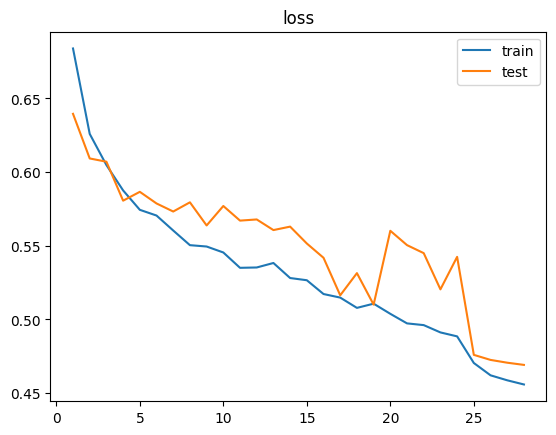

In [83]:
x = range(1, len(train_losses) + 1)
plt.plot(x, train_losses, label='train')
plt.plot(x, test_losses, label='test')
plt.legend()
plt.title('loss')

In [26]:
torch.save(best_model.state_dict(), '/kaggle/working/my_unet.pth')

In [28]:
print(f"Лучший dice: {best_dice}")

Лучший dice: 0.7104241251945496


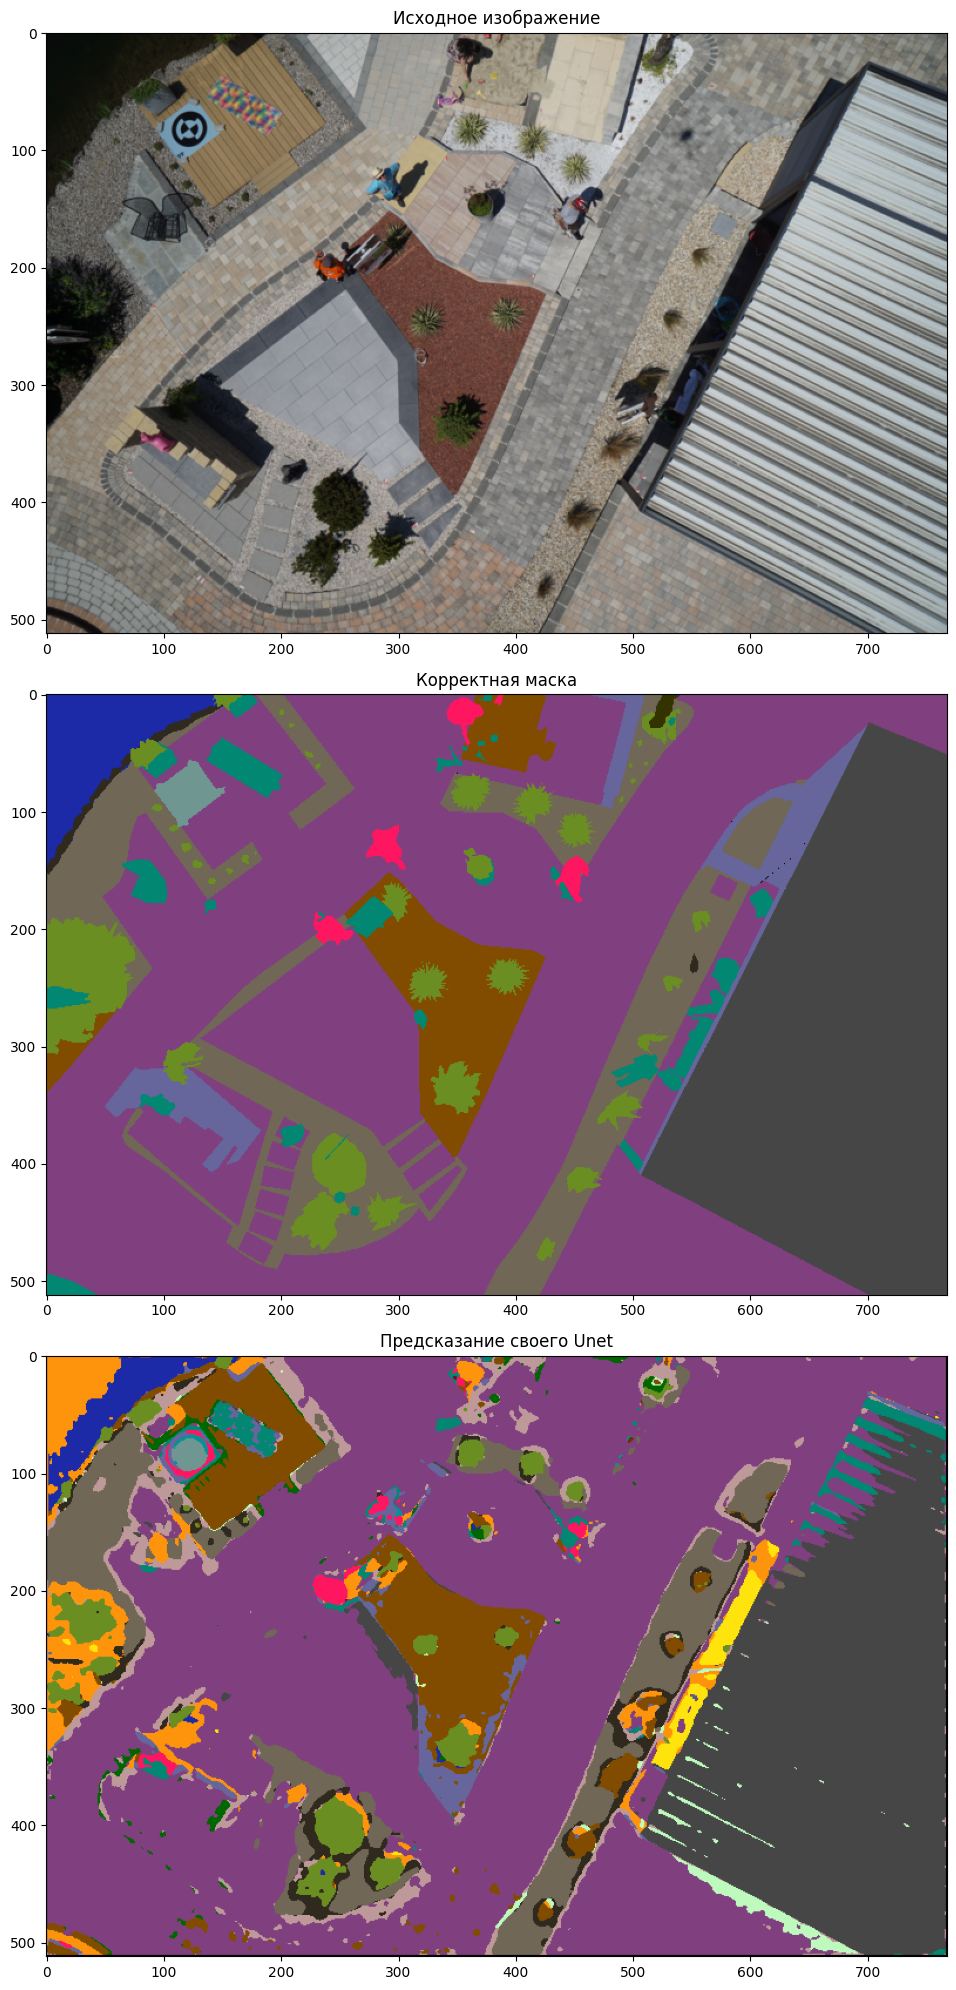

In [80]:
idx = torch.randint(0, len(test_dataset), size=(1,)).item()
rand_img = test_dataset[idx][0].to(device)
true_mask = test_dataset[idx][1]
pred_logits = best_model(rand_img.unsqueeze(0))
pred_mask = pred_logits.argmax(1).cpu().numpy()

pil_img = rand_img.permute(1, 2, 0).cpu().numpy()

fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(50, 20))

axes[0].imshow(pil_img)
axes[0].set_title('Исходное изображение')

mask_1 = label_mask_to_color_img(true_mask, (512, 768))
axes[1].imshow(mask_1, alpha=1)
axes[1].set_title('Корректная маска')

mask_2 = label_mask_to_color_img(pred_mask[0], (512, 768))
axes[2].imshow(mask_2, alpha=1)
axes[2].set_title('Предсказание своего Unet')

plt.tight_layout()

# PSPNet + efficientnet-b0

In [92]:
model_pspnet = smp.PSPNet(encoder_name='efficientnet-b0', classes=24).to(device)
loss_fn = smp.losses.DiceLoss(mode='multiclass')
optimizer = torch.optim.AdamW(model_pspnet.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'min', patience=3, min_lr=1e-7, threshold=1e-4)
train_losses_psp = []
test_losses_psp = []

In [93]:
num_epochs = 20

best_model_psp = None
best_dice_psp = -1
for i in range(num_epochs):
    print(f"Epoch {i + 1}")
    train_loop(model_pspnet, train_dataloader, loss_fn, optimizer, train_losses_psp, batch_size, len_dataset)
    val_loss = test_loop(model_pspnet, test_dataloader, loss_fn, test_losses_psp)
    if val_loss[1] > best_dice_psp:
        best_model_psp = copy.deepcopy(model_pspnet)
        best_dice_psp = val_loss[1]
    scheduler.step(val_loss[0])
    print('-' * 30)

Epoch 1
32/320 | loss: 0.70806
64/320 | loss: 0.58372
96/320 | loss: 0.68004
128/320 | loss: 0.56086
160/320 | loss: 0.57310
192/320 | loss: 0.62798
224/320 | loss: 0.72947
256/320 | loss: 0.59623
288/320 | loss: 0.51238
320/320 | loss: 0.51367
Avg train loss: 0.61762

Avg test loss: 0.71321
Avg IoU coef: 0.31891
Avg dice coef: 0.48360
------------------------------
Epoch 2
32/320 | loss: 0.56900
64/320 | loss: 0.42896
96/320 | loss: 0.57194
128/320 | loss: 0.51934
160/320 | loss: 0.51704
192/320 | loss: 0.57175
224/320 | loss: 0.64883
256/320 | loss: 0.53819
288/320 | loss: 0.46053
320/320 | loss: 0.46279
Avg train loss: 0.54059

Avg test loss: 0.67530
Avg IoU coef: 0.38055
Avg dice coef: 0.55130
------------------------------
Epoch 3
32/320 | loss: 0.51572
64/320 | loss: 0.39449
96/320 | loss: 0.54017
128/320 | loss: 0.49306
160/320 | loss: 0.47877
192/320 | loss: 0.53157
224/320 | loss: 0.61574
256/320 | loss: 0.47544
288/320 | loss: 0.45567
320/320 | loss: 0.46646
Avg train loss: 0

Text(0.5, 1.0, 'loss')

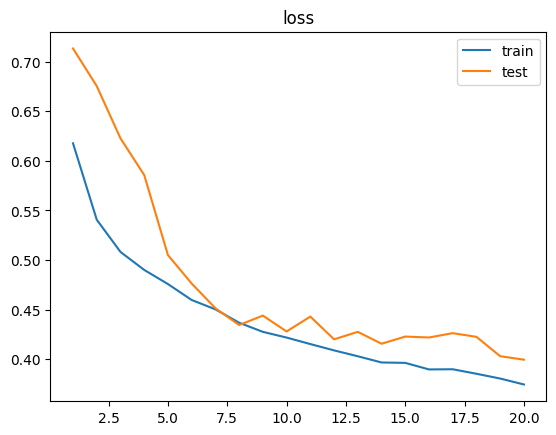

In [95]:
x = range(1, len(train_losses_psp) + 1)
plt.plot(x, train_losses_psp, label='train')
plt.plot(x, test_losses_psp, label='test')
plt.legend()
plt.title('loss')

In [96]:
torch.save(best_model_psp.state_dict(), '/kaggle/working/pspnet_eff.pth')

In [97]:
print(f"Лучший dice: {best_dice_psp}")

Лучший dice: 0.8450729250907898


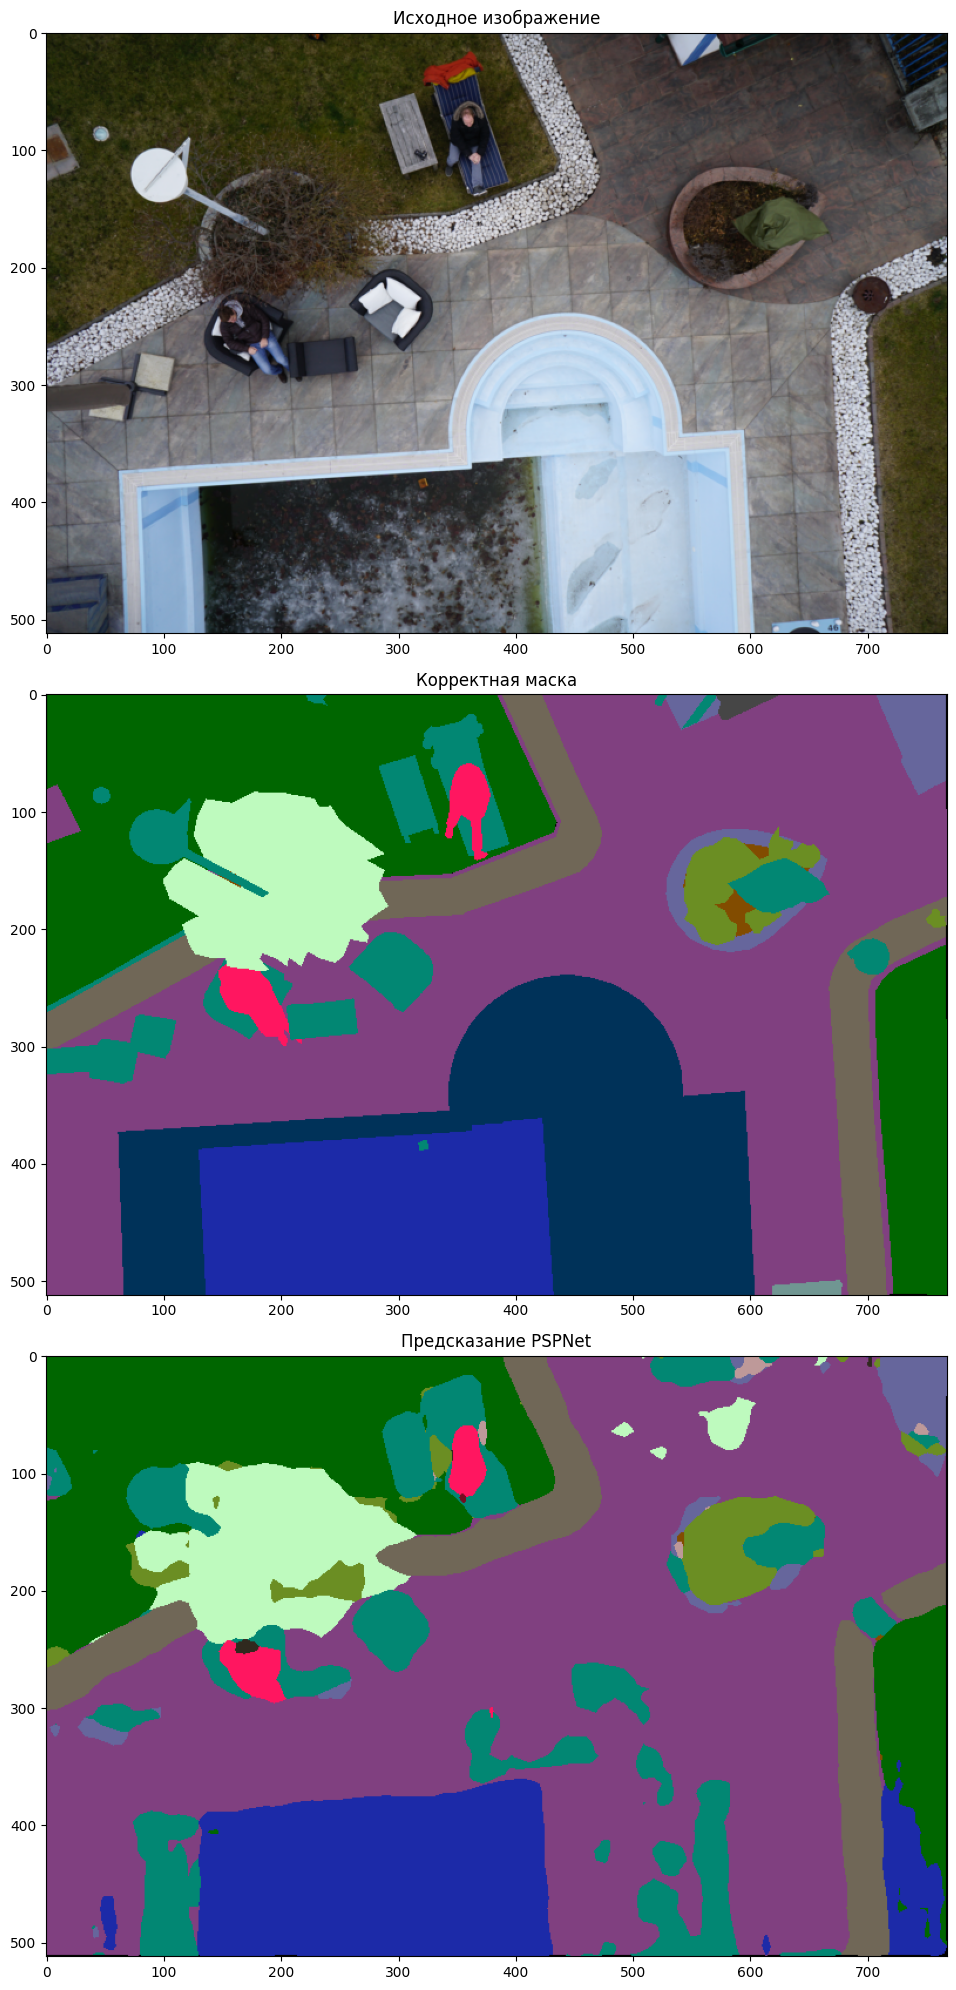

In [101]:
idx = torch.randint(0, len(test_dataset), size=(1,)).item()
rand_img = test_dataset[idx][0].to(device)
true_mask = test_dataset[idx][1]
pred_logits = best_model_psp(rand_img.unsqueeze(0))
pred_mask = pred_logits.argmax(1).cpu().numpy()

pil_img = rand_img.permute(1, 2, 0).cpu().numpy()

fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(50, 20))

axes[0].imshow(pil_img)
axes[0].set_title('Исходное изображение')

mask_1 = label_mask_to_color_img(true_mask, (512, 768))
axes[1].imshow(mask_1, alpha=1)
axes[1].set_title('Корректная маска')

mask_2 = label_mask_to_color_img(pred_mask[0], (512, 768))
axes[2].imshow(mask_2, alpha=1)
axes[2].set_title('Предсказание PSPNet')

plt.tight_layout()

# Segformer + mit_b1

In [19]:
model_segformer = smp.Segformer(encoder_name='mit_b1', classes=24).to(device)
loss_fn = smp.losses.JaccardLoss(mode='multiclass')
optimizer = torch.optim.AdamW(model_segformer.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs, eta_min=1e-7)
train_losses_segformer = []
test_losses_segformer = []

In [20]:
num_epochs = 20

best_model_segformer = None
best_dice_segformer = -1
for i in range(num_epochs):
    print(f"Epoch {i + 1}")
    train_loop(model_segformer, train_dataloader, loss_fn, optimizer, train_losses_segformer, batch_size, len_dataset)
    val_loss = test_loop(model_segformer, test_dataloader, loss_fn, test_losses_segformer)
    if val_loss[1] > best_dice_segformer:
        best_model_segformer = copy.deepcopy(model_segformer)
        best_dice_segformer = val_loss[1]
    scheduler.step()
    print('-' * 30)

Epoch 1
32/320 | loss: 0.72747
64/320 | loss: 0.64983
96/320 | loss: 0.73887
128/320 | loss: 0.64930
160/320 | loss: 0.69654
192/320 | loss: 0.71052
224/320 | loss: 0.82313
256/320 | loss: 0.74306
288/320 | loss: 0.57481
320/320 | loss: 0.64580
Avg train loss: 0.70251

Avg test loss: 0.66911
Avg IoU coef: 0.36186
Avg dice coef: 0.53142
------------------------------
Epoch 2
32/320 | loss: 0.66434
64/320 | loss: 0.53400
96/320 | loss: 0.66232
128/320 | loss: 0.55268
160/320 | loss: 0.65612
192/320 | loss: 0.67288
224/320 | loss: 0.75141
256/320 | loss: 0.67555
288/320 | loss: 0.57320
320/320 | loss: 0.60983
Avg train loss: 0.64718

Avg test loss: 0.64138
Avg IoU coef: 0.39953
Avg dice coef: 0.57095
------------------------------
Epoch 3
32/320 | loss: 0.60317
64/320 | loss: 0.48022
96/320 | loss: 0.61789
128/320 | loss: 0.50237
160/320 | loss: 0.59107
192/320 | loss: 0.64573
224/320 | loss: 0.74080
256/320 | loss: 0.63280
288/320 | loss: 0.49165
320/320 | loss: 0.52598
Avg train loss: 0

Text(0.5, 1.0, 'loss')

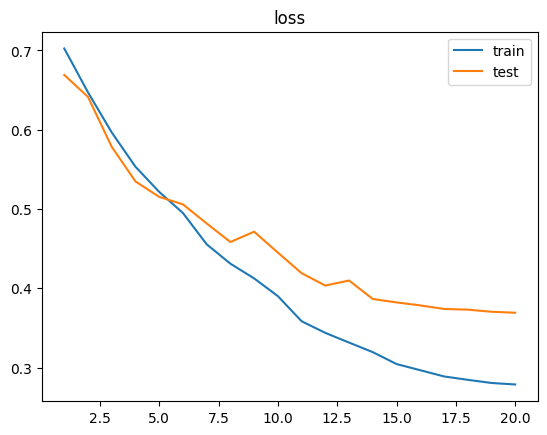

In [21]:
x = range(1, len(train_losses_segformer) + 1)
plt.plot(x, train_losses_segformer, label='train')
plt.plot(x, test_losses_segformer, label='test')
plt.legend()
plt.title('loss')

In [22]:
torch.save(best_model_segformer.state_dict(), '/kaggle/working/segformer.pth')

In [24]:
print(f"Лучший dice: {best_dice_segformer}")

Лучший dice: 0.8742706179618835


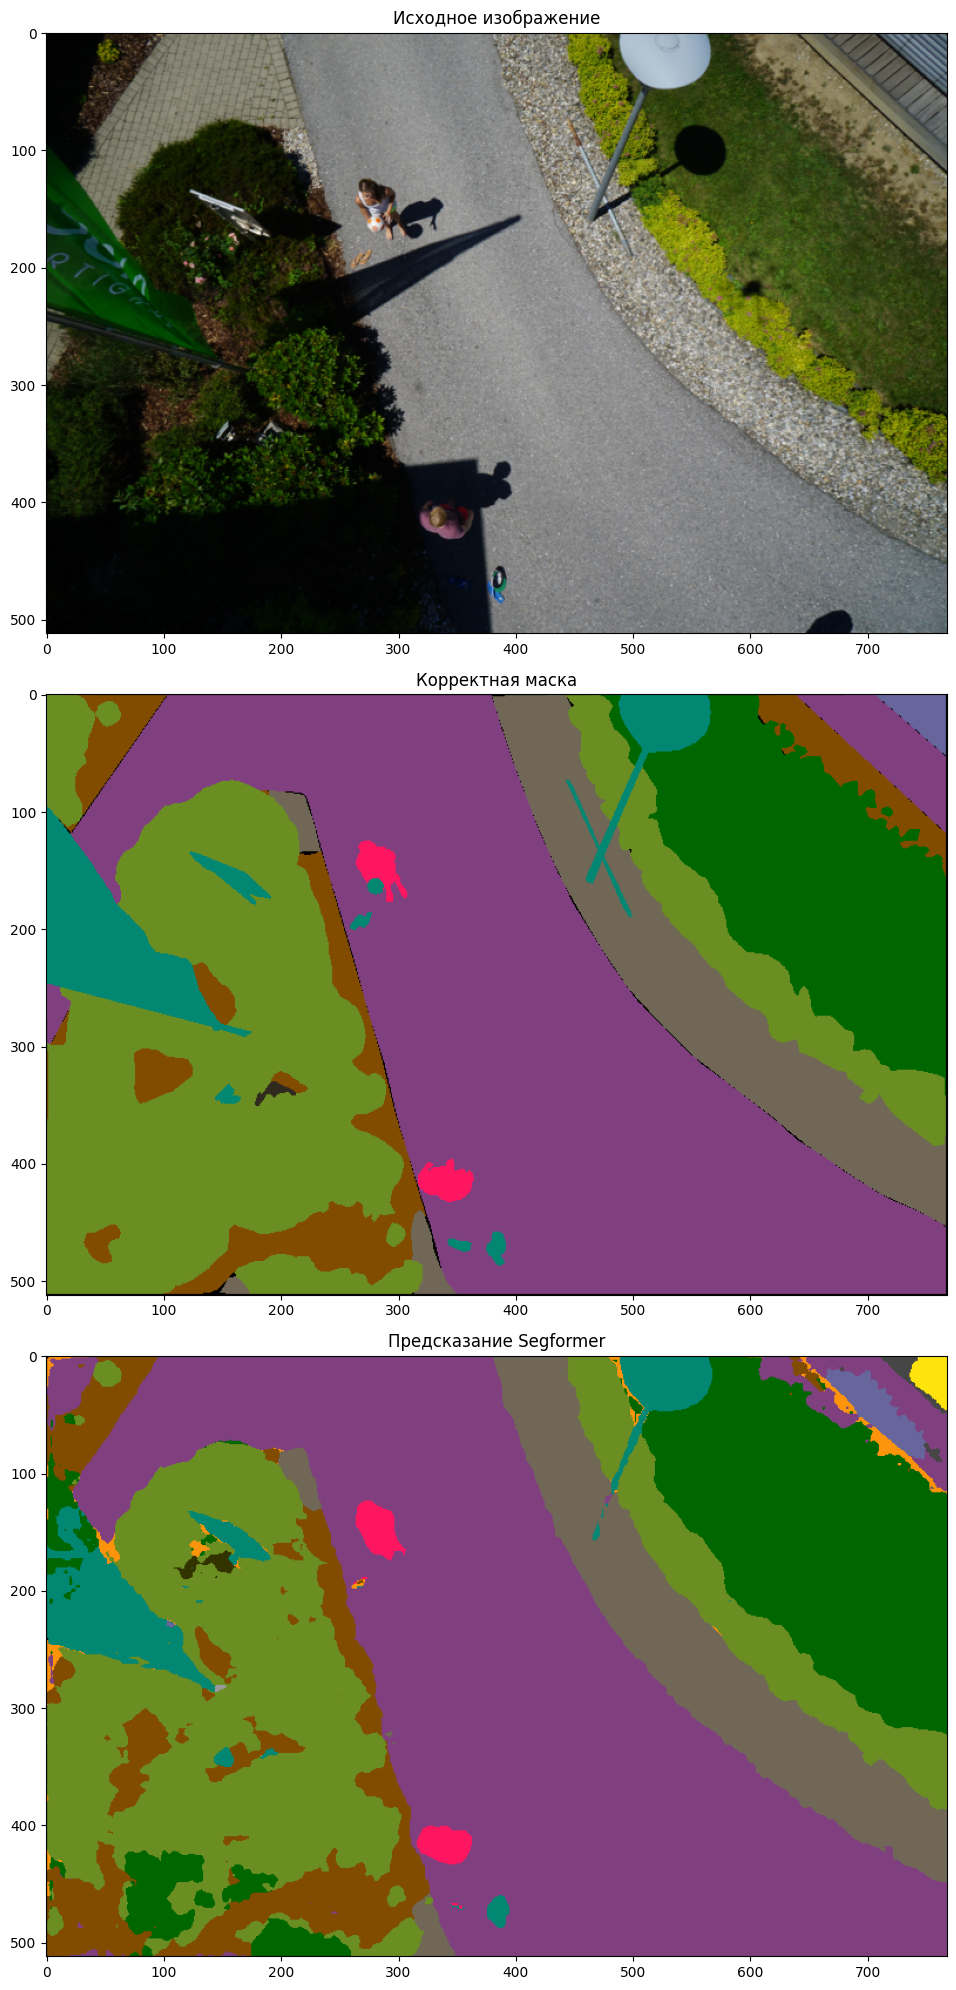

In [25]:
idx = torch.randint(0, len(test_dataset), size=(1,)).item()
rand_img = test_dataset[idx][0].to(device)
true_mask = test_dataset[idx][1]
pred_logits = best_model_segformer(rand_img.unsqueeze(0))
pred_mask = pred_logits.argmax(1).cpu().numpy()

pil_img = rand_img.permute(1, 2, 0).cpu().numpy()

fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(50, 20))

axes[0].imshow(pil_img)
axes[0].set_title('Исходное изображение')

mask_1 = label_mask_to_color_img(true_mask, (512, 768))
axes[1].imshow(mask_1, alpha=1)
axes[1].set_title('Корректная маска')

mask_2 = label_mask_to_color_img(pred_mask[0], (512, 768))
axes[2].imshow(mask_2, alpha=1)
axes[2].set_title('Предсказание Segformer')

plt.tight_layout()

# Сравнение моделей

| Модель | Dice Coefficient | IoU |
| :--- | :---: | :---: |
| **Custom U-Net** | 0.71042 | 0.55090 |
| **PSPNet** | 0.84507 | 0.73171 |
| **UnetPlusPlus** | 0.87427 | 0.77663 |